In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms, datasets
from torchvision.datasets.utils import download_and_extract_archive
from torch.utils.data import DataLoader
from PIL import Image
from google.colab import files

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [2]:
# In PyTorch, all ImageNet models use the same preprocessing
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


def load_and_preprocess_image(img_path):
    img = Image.open(img_path).convert('RGB')
    img_tensor = preprocess(img)
    return img_tensor.unsqueeze(0).to(device)


# The 1000 ImageNet class names
imagenet_classes = models.ResNet50_Weights.IMAGENET1K_V1.meta['categories']

In [3]:
vgg_model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).to(device).eval()
resnet_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1).to(device).eval()

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 84.0MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 170MB/s]


In [4]:
def make_predictions(model, img_tensor, top=5):
    with torch.no_grad():
        probs = torch.softmax(model(img_tensor), dim=1)[0]
    top_probs, top_idx = probs.topk(top)
    return [(imagenet_classes[i], p.item()) for i, p in zip(top_idx.tolist(), top_probs)]


def print_top_5_predictions(model, img_path, model_name):
    img_tensor = load_and_preprocess_image(img_path)
    predictions = make_predictions(model, img_tensor)

    print(f"Top 5 predictions from {model_name}:")
    for i, (label, prob) in enumerate(predictions):
        print(f"{i + 1}. {label} ({prob * 100:.2f}% probability)")
    return predictions

Saving original.jpg to original.jpg


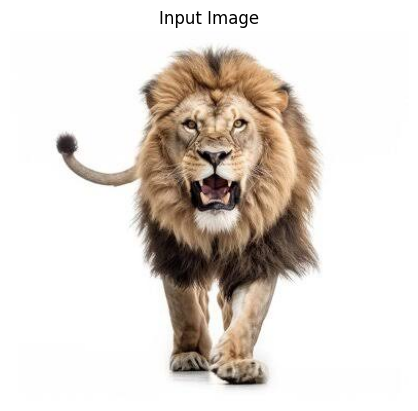

In [5]:
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

plt.imshow(Image.open(img_path))
plt.title('Input Image')
plt.axis('off')
plt.show()

In [6]:
vgg_predictions = print_top_5_predictions(vgg_model, img_path, 'VGG16')
print()
resnet_predictions = print_top_5_predictions(resnet_model, img_path, 'ResNet50')

Top 5 predictions from VGG16:
1. lion (99.98% probability)
2. chow (0.02% probability)
3. tiger (0.00% probability)
4. Tibetan mastiff (0.00% probability)
5. Persian cat (0.00% probability)

Top 5 predictions from ResNet50:
1. lion (99.87% probability)
2. Tibetan mastiff (0.06% probability)
3. cheetah (0.02% probability)
4. chow (0.02% probability)
5. tiger (0.01% probability)


## Block 7: Task 2 - AlexNet, ResNet101 and MobileNet

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 189MB/s]


Downloading: "https://download.pytorch.org/models/resnet101-63fe2227.pth" to /root/.cache/torch/hub/checkpoints/resnet101-63fe2227.pth


100%|██████████| 171M/171M [00:02<00:00, 65.4MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 120MB/s]


Top 5 predictions from VGG16:
1. lion (99.98% probability)
2. chow (0.02% probability)
3. tiger (0.00% probability)
4. Tibetan mastiff (0.00% probability)
5. Persian cat (0.00% probability)

Top 5 predictions from ResNet50:
1. lion (99.87% probability)
2. Tibetan mastiff (0.06% probability)
3. cheetah (0.02% probability)
4. chow (0.02% probability)
5. tiger (0.01% probability)

Top 5 predictions from AlexNet:
1. lion (99.71% probability)
2. chow (0.28% probability)
3. keeshond (0.01% probability)
4. Tibetan mastiff (0.00% probability)
5. cougar (0.00% probability)

Top 5 predictions from ResNet101:
1. lion (99.97% probability)
2. tiger (0.02% probability)
3. chow (0.00% probability)
4. leopard (0.00% probability)
5. cheetah (0.00% probability)

Top 5 predictions from MobileNetV2:
1. lion (98.68% probability)
2. cheetah (0.55% probability)
3. tiger (0.24% probability)
4. lynx (0.14% probability)
5. chow (0.06% probability)

Model              Params       Top-1 prediction  Confidence  T

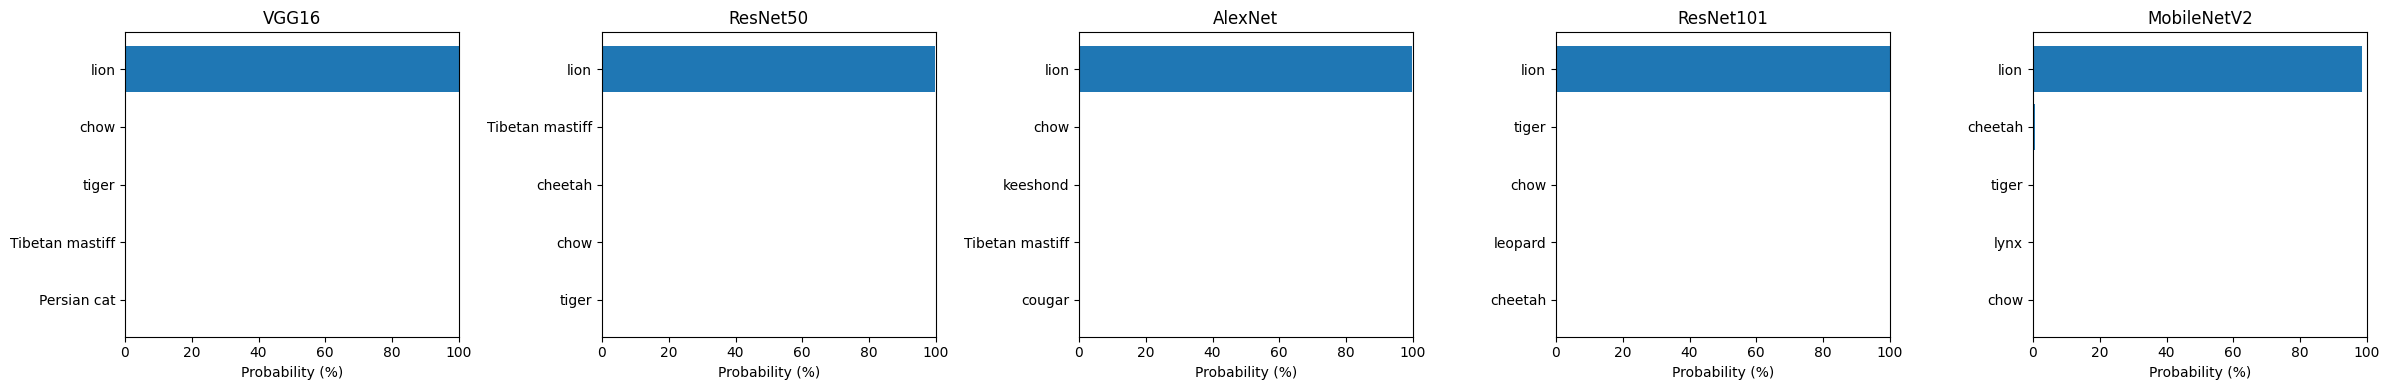

In [7]:
all_models = {
    'VGG16': vgg_model,
    'ResNet50': resnet_model,
    'AlexNet': models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1),
    'ResNet101': models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V1),
    'MobileNetV2': models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1),
}

img_tensor = load_and_preprocess_image(img_path)
all_predictions = {}
comparison = []

for name, m in all_models.items():
    m.to(device).eval()
    preds = print_top_5_predictions(m, img_path, name)
    print()
    all_predictions[name] = preds

    # Average inference time over 20 runs (after one warm-up run)
    with torch.no_grad():
        m(img_tensor)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.time()
        for _ in range(20):
            m(img_tensor)
        if device.type == 'cuda':
            torch.cuda.synchronize()
    inference_ms = (time.time() - start) / 20 * 1000

    params = sum(p.numel() for p in m.parameters())
    comparison.append((name, params, preds[0][0], preds[0][1], inference_ms))

print(f"{'Model':12} {'Params':>12} {'Top-1 prediction':>22} {'Confidence':>11} {'Time (ms)':>10}")
for name, params, label, prob, t in comparison:
    print(f"{name:12} {params:12,} {label:>22} {prob * 100:10.2f}% {t:10.2f}")

fig, axes = plt.subplots(1, 5, figsize=(24, 4))
for ax, (name, preds) in zip(axes, all_predictions.items()):
    labels = [label for label, _ in preds][::-1]
    probs = [prob * 100 for _, prob in preds][::-1]
    ax.barh(labels, probs)
    ax.set_xlim(0, 100)
    ax.set_title(name)
    ax.set_xlabel('Probability (%)')
plt.tight_layout()
plt.show()

## Block 8: Task 3 - Download a dataset for transfer learning

100%|██████████| 47.3M/47.3M [00:00<00:00, 255MB/s]


Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


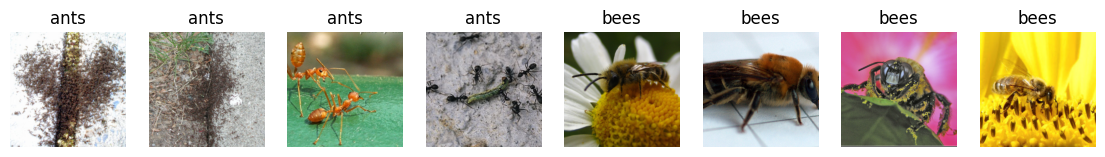

In [8]:
# Ants vs Bees dataset (about 400 images)
download_and_extract_archive('https://download.pytorch.org/tutorial/hymenoptera_data.zip', download_root='./data')
data_dir = './data/hymenoptera_data'

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_data = datasets.ImageFolder(os.path.join(data_dir, 'train'), train_transform)
val_data = datasets.ImageFolder(os.path.join(data_dir, 'val'), preprocess)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_data, batch_size=16, shuffle=False, num_workers=2)

class_names = train_data.classes
print('Classes:', class_names)
print('Training images:', len(train_data))
print('Validation images:', len(val_data))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def to_image(tensor):
    return (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)


sample_idx = np.linspace(0, len(val_data) - 1, 8).astype(int)
plt.figure(figsize=(14, 4))
for j, idx in enumerate(sample_idx):
    image, label = val_data[idx]
    plt.subplot(1, 8, j + 1)
    plt.imshow(to_image(image))
    plt.title(class_names[label])
    plt.axis('off')
plt.show()

## Block 9: Training function

In [9]:
criterion = nn.CrossEntropyLoss()


def train_model(model, optimizer, epochs=10):
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    start = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                val_loss += criterion(outputs, labels).item() * labels.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        history['loss'].append(total_loss / total)
        history['accuracy'].append(correct / total)
        history['val_loss'].append(val_loss / val_total)
        history['val_accuracy'].append(val_correct / val_total)
        print(f"Epoch {epoch + 1}/{epochs} - loss: {total_loss / total:.4f} - accuracy: {correct / total:.4f}"
              f" - val_loss: {val_loss / val_total:.4f} - val_accuracy: {val_correct / val_total:.4f}")

    history['time'] = time.time() - start
    return history


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Block 10: Train ResNet50 three ways

In [10]:
num_classes = len(class_names)

# a) From scratch: no pretrained weights
print("Training: ResNet50 from scratch")
scratch_model = models.resnet50(weights=None)
scratch_model.fc = nn.Linear(scratch_model.fc.in_features, num_classes)
scratch_model = scratch_model.to(device)
scratch_history = train_model(scratch_model, optim.Adam(scratch_model.parameters(), lr=0.001))

# b) Feature extraction: freeze the pretrained layers, train only the new last layer
print("\nTraining: Feature extraction (frozen ResNet50)")
fe_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
for param in fe_model.parameters():
    param.requires_grad = False
fe_model.fc = nn.Linear(fe_model.fc.in_features, num_classes)
fe_model = fe_model.to(device)
fe_history = train_model(fe_model, optim.Adam(fe_model.fc.parameters(), lr=0.001))

# c) Fine-tuning: start from pretrained weights and train all layers with a small learning rate
print("\nTraining: Fine-tuning (all ResNet50 layers)")
ft_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
ft_model.fc = nn.Linear(ft_model.fc.in_features, num_classes)
ft_model = ft_model.to(device)
ft_history = train_model(ft_model, optim.Adam(ft_model.parameters(), lr=0.0001))

Training: ResNet50 from scratch
Epoch 1/10 - loss: 1.7518 - accuracy: 0.5287 - val_loss: 34.6962 - val_accuracy: 0.4575
Epoch 2/10 - loss: 1.0658 - accuracy: 0.5656 - val_loss: 2.1186 - val_accuracy: 0.5686
Epoch 3/10 - loss: 0.8809 - accuracy: 0.5738 - val_loss: 1.1330 - val_accuracy: 0.7124
Epoch 4/10 - loss: 0.7765 - accuracy: 0.5779 - val_loss: 1.0240 - val_accuracy: 0.5556
Epoch 5/10 - loss: 0.7006 - accuracy: 0.6066 - val_loss: 0.5827 - val_accuracy: 0.6993
Epoch 6/10 - loss: 0.6477 - accuracy: 0.6434 - val_loss: 0.7264 - val_accuracy: 0.6013
Epoch 7/10 - loss: 0.6324 - accuracy: 0.6844 - val_loss: 0.7235 - val_accuracy: 0.6275
Epoch 8/10 - loss: 0.6669 - accuracy: 0.6311 - val_loss: 0.8181 - val_accuracy: 0.6078
Epoch 9/10 - loss: 0.6458 - accuracy: 0.6434 - val_loss: 0.6006 - val_accuracy: 0.7255
Epoch 10/10 - loss: 0.5761 - accuracy: 0.6557 - val_loss: 0.5979 - val_accuracy: 0.6601

Training: Feature extraction (frozen ResNet50)
Epoch 1/10 - loss: 0.5218 - accuracy: 0.7377 - v

## Block 11: Compare the three approaches

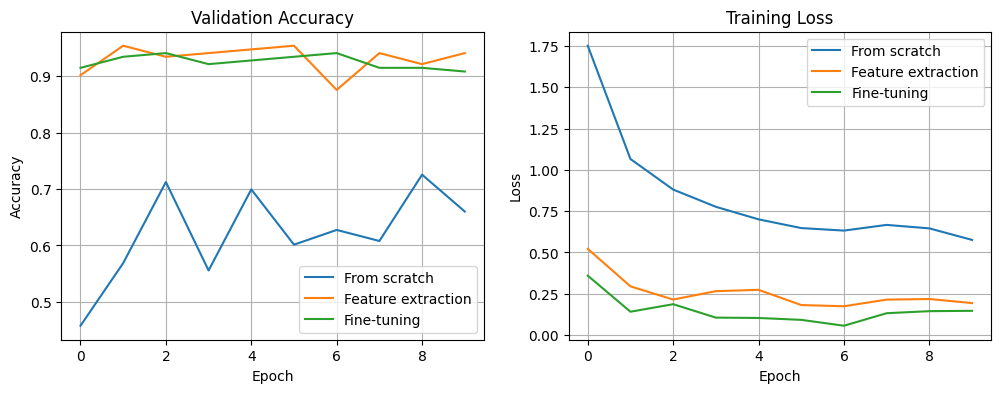

Approach              Trainable params  Best val acc  Final val acc  Time (s)
From scratch                23,512,130        0.7255         0.6601      41.3
Feature extraction               4,098        0.9542         0.9412      24.9
Fine-tuning                 23,512,130        0.9412         0.9085      41.0


In [11]:
runs = {
    'From scratch': (scratch_model, scratch_history),
    'Feature extraction': (fe_model, fe_history),
    'Fine-tuning': (ft_model, ft_history),
}

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for name, (_, h) in runs.items():
    plt.plot(h['val_accuracy'], label=name)
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
for name, (_, h) in runs.items():
    plt.plot(h['loss'], label=name)
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

print(f"{'Approach':20} {'Trainable params':>17} {'Best val acc':>13} {'Final val acc':>14} {'Time (s)':>9}")
for name, (m, h) in runs.items():
    print(f"{name:20} {count_trainable(m):17,} {max(h['val_accuracy']):13.4f} "
          f"{h['val_accuracy'][-1]:14.4f} {h['time']:9.1f}")

## Block 12: Predictions with the fine-tuned model

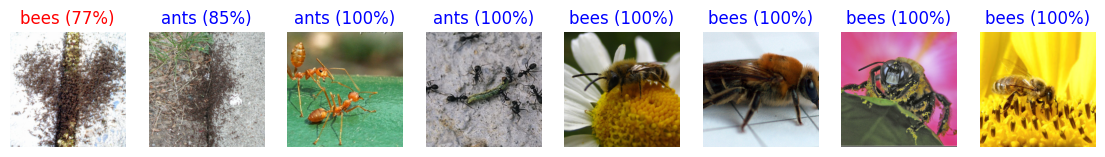

In [12]:
ft_model.eval()
plt.figure(figsize=(14, 4))
for j, idx in enumerate(sample_idx):
    image, label = val_data[idx]
    with torch.no_grad():
        probs = torch.softmax(ft_model(image.unsqueeze(0).to(device)), dim=1)[0]
    pred = probs.argmax().item()
    color = 'blue' if pred == label else 'red'

    plt.subplot(1, 8, j + 1)
    plt.imshow(to_image(image))
    plt.title(f"{class_names[pred]} ({probs[pred] * 100:.0f}%)", color=color)
    plt.axis('off')
plt.show()